# Chapitre 8 - Cours 2 : l'algorithme EM et l'échantillonneur de Gibbs

Ce notebook couvre les sections 8.5 et 8.6 du livre :

1. le **mélange de deux gaussiennes** sur les 20 données fictives du tableau 8.1 ;
2. l'**algorithme EM** (*Expectation-Maximization*) pour ce mélange (algorithme 8.1,
   figures 8.5 et 8.6, tableau 8.2) ;
3. pourquoi EM fonctionne **en général** (algorithme 8.2, inégalité de Jensen) et sa
   lecture comme une double maximisation ;
4. les méthodes de **Monte-Carlo par chaînes de Markov** (MCMC) et l'**échantillonneur
   de Gibbs**, cousin « aléatoire » d'EM (algorithmes 8.3 et 8.4, figure 8.8).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import ch08_inference as inf
set_style()
rng = np.random.RandomState(0)

## 1. Les données et le modèle de mélange

Le tableau 8.1 du livre contient 20 nombres fictifs. Leur histogramme (figure 8.5,
panneau de gauche) présente **deux bosses** : une seule loi normale serait inadaptée.

In [2]:
y = np.sort(inf.MIXTURE_DATA)
N = len(y)
print(y)

[-0.39  0.06  0.12  0.48  0.94  1.01  1.67  1.68  1.76  1.8   2.44  3.25
  3.72  4.12  4.28  4.6   4.92  5.28  5.53  6.22]


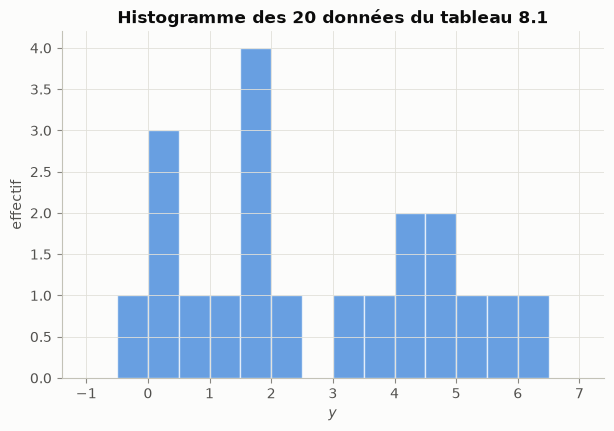

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(y, bins=np.arange(-1, 7.5, 0.5), color=BLUE, alpha=0.7, edgecolor="white")
ax.set(title="Histogramme des 20 données du tableau 8.1", xlabel="$y$", ylabel="effectif")
plt.show()

### Mélange de deux lois normales

On suppose que chaque observation provient de l'un de deux « régimes » :

$$Y_1 \sim N(\mu_1, \sigma_1^2), \qquad Y_2 \sim N(\mu_2, \sigma_2^2), \qquad
Y = (1 - \Delta)\,Y_1 + \Delta\,Y_2, \qquad \text{(éq. (8.36))}$$

où $\Delta \in \{0, 1\}$ est une variable de Bernoulli indépendante, avec
$\Pr(\Delta = 1) = \pi$. Autrement dit : on tire d'abord $\Delta$ (« pile ou face
biaisé »), puis on renvoie $Y_1$ si $\Delta = 0$ et $Y_2$ si $\Delta = 1$.

Notons $\phi_\theta$ la densité de $N(\mu, \sigma^2)$, $\theta = (\mu, \sigma^2)$. Par la
formule des probabilités totales (on conditionne par $\Delta$) :

$$g_Y(y) = (1 - \pi)\,\phi_{\theta_1}(y) + \pi\,\phi_{\theta_2}(y). \qquad
\text{(éq. (8.37))}$$

Illustrons le mécanisme génératif : on simule 2000 valeurs avec des paramètres proches
de ceux que nous estimerons, en coloriant selon la valeur (cachée) de $\Delta$.

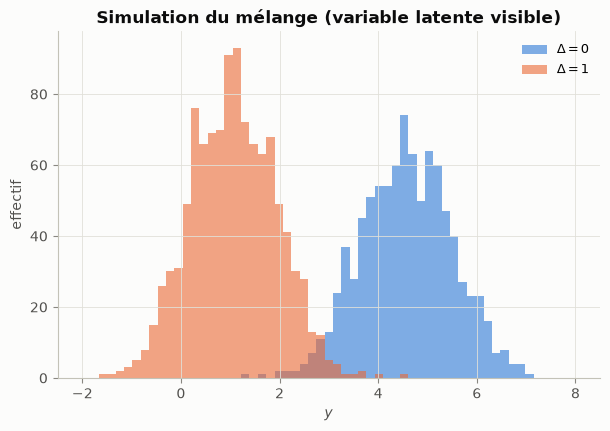

In [4]:
theta_demo = (4.6, 0.8, 1.1, 0.8, 0.55)        # (mu1, var1, mu2, var2, pi)
D = rng.rand(2000) < theta_demo[4]
Ysim = np.where(D, theta_demo[2] + np.sqrt(theta_demo[3]) * rng.randn(2000),
                theta_demo[0] + np.sqrt(theta_demo[1]) * rng.randn(2000))
tt = np.linspace(-2, 8, 400)
fig, ax = plt.subplots(figsize=(7, 4.5))
bins = np.linspace(-2, 8, 60)
ax.hist(Ysim[~D], bins=bins, density=False, color=BLUE, alpha=0.6, label=r"$\Delta = 0$")
ax.hist(Ysim[D], bins=bins, density=False, color=ORANGE, alpha=0.6, label=r"$\Delta = 1$")
ax.set(title="Simulation du mélange (variable latente visible)", xlabel="$y$",
       ylabel="effectif")
ax.legend()
plt.show()

### La log-vraisemblance

Les paramètres sont $\theta = (\pi, \theta_1, \theta_2) = (\pi, \mu_1, \sigma_1^2, \mu_2,
\sigma_2^2)$ (éq. (8.38)) et la log-vraisemblance des $N$ observations vaut

$$\ell(\theta; Z) = \sum_{i=1}^N \log\big[(1 - \pi)\phi_{\theta_1}(y_i) +
\pi\,\phi_{\theta_2}(y_i)\big]. \qquad \text{(éq. (8.39))}$$

La **somme à l'intérieur du logarithme** empêche d'obtenir des formules explicites :
les équations $\partial\ell/\partial\theta = 0$ couplent tous les paramètres.

### L'astuce : les variables latentes

Si l'on connaissait les $\Delta_i$ (variables **latentes**, c'est-à-dire non observées),
la log-vraisemblance « complète » serait

$$\ell_0(\theta; Z, \Delta) = \sum_{i=1}^N \big[(1-\Delta_i)\log\phi_{\theta_1}(y_i) +
\Delta_i\log\phi_{\theta_2}(y_i)\big] + \sum_{i=1}^N\big[(1-\Delta_i)\log(1-\pi) +
\Delta_i\log\pi\big]. \qquad \text{(éq. (8.40))}$$

Elle se sépare en trois morceaux indépendants : $\hat\mu_1, \hat\sigma_1^2$ seraient la
moyenne et la variance empiriques des points où $\Delta_i = 0$, de même pour
$\hat\mu_2, \hat\sigma_2^2$, et $\hat\pi$ la proportion de $\Delta_i = 1$.

### Les responsabilités

Ne connaissant pas les $\Delta_i$, on les remplace par leur espérance conditionnelle

$$\gamma_i(\theta) = E(\Delta_i\mid\theta, Z) = \Pr(\Delta_i = 1\mid\theta, Z),
\qquad \text{(éq. (8.41))}$$

appelée **responsabilité** de la composante 2 pour l'observation $i$. Par la formule de
Bayes, $\Pr(\Delta_i = 1\mid y_i) = \frac{\Pr(\Delta_i = 1)\,g(y_i\mid\Delta_i = 1)}
{g_Y(y_i)}$, soit

$$\hat\gamma_i = \frac{\hat\pi\,\phi_{\hat\theta_2}(y_i)}{(1-\hat\pi)\phi_{\hat\theta_1}(y_i)
+ \hat\pi\,\phi_{\hat\theta_2}(y_i)}. \qquad \text{(éq. (8.42))}$$

## 2. L'algorithme EM pour le mélange (algorithme 8.1)

1. **Initialisation** : $\hat\mu_1, \hat\mu_2$ = deux observations tirées au hasard,
   $\hat\sigma_1^2 = \hat\sigma_2^2$ = variance empirique globale, $\hat\pi = 0{,}5$.
2. **Étape E** (*Expectation*) : calculer les responsabilités $\hat\gamma_i$ par (8.42)
   - une affectation « douce » de chaque point aux deux composantes.
3. **Étape M** (*Maximization*) : moyennes et variances **pondérées**
   $$\hat\mu_1 = \frac{\sum_i (1-\hat\gamma_i)y_i}{\sum_i(1-\hat\gamma_i)}, \quad
   \hat\sigma_1^2 = \frac{\sum_i(1-\hat\gamma_i)(y_i-\hat\mu_1)^2}{\sum_i(1-\hat\gamma_i)},
   \quad \hat\mu_2 = \frac{\sum_i\hat\gamma_iy_i}{\sum_i\hat\gamma_i}, \quad
   \hat\sigma_2^2 = \frac{\sum_i\hat\gamma_i(y_i-\hat\mu_2)^2}{\sum_i\hat\gamma_i},$$
   et $\hat\pi = \frac1N\sum_i\hat\gamma_i$.
4. Répéter 2 et 3 jusqu'à convergence.

L'implémentation se trouve dans `esl.ch08_inference.em_mixture`.

Comme dans le livre, on lance EM depuis plusieurs initialisations et on garde la
meilleure log-vraisemblance.

In [5]:
runs = []
for s in range(10):
    i, j = rng.choice(N, 2, replace=False)
    r = inf.em_mixture(y, (y[i], y.var(), y[j], y.var(), 0.5), n_iter=200, tol=1e-10)
    runs.append(r)
    print("départ mu=(%5.2f, %5.2f) -> mu1=%.3f mu2=%.3f pi=%.3f   loglik=%.4f"
          % (y[i], y[j], r["theta"][0], r["theta"][2], r["theta"][4], r["loglik"][-1]))

départ mu=( 1.67,  4.60) -> mu1=1.083 mu2=4.656 pi=0.445   loglik=-38.9134
départ mu=( 5.53,  4.92) -> mu1=4.656 mu2=1.083 pi=0.555   loglik=-38.9134
départ mu=( 1.68,  3.25) -> mu1=1.083 mu2=4.656 pi=0.445   loglik=-38.9134
départ mu=( 0.12,  1.01) -> mu1=1.083 mu2=4.656 pi=0.445   loglik=-38.9134
départ mu=( 2.44,  0.12) -> mu1=4.656 mu2=1.083 pi=0.555   loglik=-38.9134
départ mu=( 0.94,  3.72) -> mu1=1.083 mu2=4.656 pi=0.445   loglik=-38.9134
départ mu=( 1.80,  1.01) -> mu1=4.656 mu2=1.083 pi=0.555   loglik=-38.9134
départ mu=( 2.44,  6.22) -> mu1=1.083 mu2=4.656 pi=0.445   loglik=-38.9134
départ mu=( 0.48,  3.72) -> mu1=1.083 mu2=4.656 pi=0.445   loglik=-38.9134
départ mu=( 3.25,  0.48) -> mu1=4.656 mu2=1.083 pi=0.555   loglik=-38.9134


Tous les départs mènent à la même solution, à une **permutation des étiquettes** près
(échanger les composantes 1 et 2 et remplacer $\pi$ par $1 - \pi$ ne change pas le
modèle). Retenons l'étiquetage du livre : composante 1 à droite, composante 2 à gauche.

In [6]:
best = max(runs, key=lambda r: r["loglik"][-1])
mu1, v1, mu2, v2, pi = best["theta"]
if mu1 < mu2:                                       # étiquetage du livre
    mu1, v1, mu2, v2, pi = mu2, v2, mu1, v1, 1 - pi
theta_hat = (mu1, v1, mu2, v2, pi)
print("mu1 = %.2f  sigma1^2 = %.2f" % (mu1, v1))
print("mu2 = %.2f  sigma2^2 = %.2f" % (mu2, v2))
print("pi  = %.3f" % pi)

mu1 = 4.66  sigma1^2 = 0.82
mu2 = 1.08  sigma2^2 = 0.81
pi  = 0.555


Le livre rapporte $\hat\mu_1 = 4{,}62$, $\hat\sigma_1^2 = 0{,}87$, $\hat\mu_2 = 1{,}06$,
$\hat\sigma_2^2 = 0{,}77$, $\hat\pi = 0{,}546$. Nos valeurs, obtenues à convergence
complète, en sont très proches ; la petite différence vient vraisemblablement de l'arrêt
du livre après une vingtaine d'itérations.

### Progression de l'algorithme (tableau 8.2 et figure 8.6)

Pour suivre une trajectoire semblable à celle du livre, partons de
$\hat\mu_1 = 4{,}5$, $\hat\mu_2 = 1$, variances égales à la variance globale et
$\hat\pi = 0{,}5$.

In [7]:
traj = inf.em_mixture(y, (4.5, y.var(), 1.0, y.var(), 0.5), n_iter=20)
print("Itération   pi_hat    log-vraisemblance")
for it in [1, 5, 10, 15, 20]:
    print("%9d   %.3f    %.3f" % (it, traj["thetas"][it, 4], traj["loglik"][it]))

Itération   pi_hat    log-vraisemblance
        1   0.518    -41.378
        5   0.524    -39.113
       10   0.550    -38.916
       15   0.554    -38.913
       20   0.555    -38.913


In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(np.arange(0, 21), traj["loglik"], color=BLUE, marker="o")
ax.set(title="EM : log-vraisemblance observée au fil des itérations",
       xlabel="itération", ylabel=r"$\ell(\hat\theta^{(j)}; Z)$")
plt.show()